<a href="https://colab.research.google.com/github/PraisePeter/Student_Exam_Performance_Prediction_Using_Logistic_Regression/blob/main/Student_Exam_Performance_Prediction_Using_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Task

Develop a simple machine learning model that predicts whether a student will pass or fail an examination based on the number of hours spent studying.

## Problem Statement

In this project, a Logistic Regression machine learning model will be developed to predict students' examination outcomes based on their study hours.
The dataset contains two variables: Study_Hours, representing the number of hours spent studying, and Passed, representing the examination outcome, where 1 indicates a pass and 0 indicates a fail.
The model will be trained using historical student data and evaluated to determine how accurately it can classify students into pass or fail categories.
The ultimate goal is to explore how study hours relate to examination performance and demonstrate how Logistic Regression can be applied to a binary classification problem.

> **QUESTION**: Can the number of hours a student spends studying predict whether they will pass or fail an examination?
>
>
>
> A university wants to understand the relationship between students' study habits and their academic performance. Specifically, the university aims to determine whether the number of hours a student spends studying can help predict whether the student will pass or fail an examination.

### Machine Learning Workflow

Whether we're solving a classification or regression problem, the general workflow for training a machine learning model follows similar steps:

1. We initialize a model using the training algorithm.
2. We pass the input data (Study Hours) into the model to obtain predictions.
3. We compare the model's predictions with the actual outcomes (Passed) to measure its performance.
4. We use an optimization technique (Gradient Descent) to adjust the model's parameters and minimize the loss.
5. We repeat the process until the model learns the relationship between study hours and examination outcomes.

In this project, we'll train a *logistic regression* model using student study hours to predict whether a student will pass or fail an examination. This is a *binary classification* problem because the model predicts one of two possible outcomes: 1 (Pass) or 0 (Fail).

We'll use the `scikit-learn` library to build, train and evaluate our model.

## Import Libraries

We'll import the different libraries we will be using for this project.

In [240]:
!pip install scikit-learn --upgrade --quiet

In [241]:
!pip install pandas --quiet

In [242]:
from google.colab import files
import os
import pandas as pd
import plotly.express as px
from sklearn.metrics import accuracy_score
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import numpy as np

## Download the Dataset

We'll use google.colab and `opendatasets` to download the dataset from google drive. Let's install and import `google drive`.


In [243]:
from google.colab import drive

In [244]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [245]:
os.listdir('/content/drive/MyDrive/Colab Notebooks/')

['Untitled0.ipynb',
 'python-sklearn-linear-regression.ipynb',
 'Copy_of_python_sklearn_linear_regression (1).ipynb',
 'Copy_of_python_sklearn_linear_regression.ipynb',
 'Copy of python-sklearn-linear-regression.ipynb',
 'First beautiful soup class.ipynb',
 'Copy of First beautiful soup class',
 'Job listings using beautiful soup .ipynb',
 'Fuel Prices in Nigeria.ipynb',
 'Nigeria_Fuel_Prices_Historical_Scraper_Refined.ipynb',
 'Copy of Nigeria_Fuel_Prices_Historical_Scraper_Refined.ipynb',
 'student_exam_results.csv',
 'python-sklearn-logistic-regression Lesson2.ipynb',
 'Student Exam Performance Prediction Using Logistic Regression.ipynb']

In [246]:
## Define your dataset folder
dataset_url = '/content/drive/MyDrive/Colab Notebooks/'

In [247]:
## Specify the CSV file
csv_path = os.path.join(dataset_url, "student_exam_results.csv")

In [248]:
## Load the dataset
student_df = pd.read_csv(csv_path)

In [249]:
student_df.head()

,Study_Hours,Passed
0,0.5,0
1,1.0,0
2,1.5,0
3,2.0,0
4,2.5,0


In [250]:
student_df


,Study_Hours,Passed
0,0.5,0
1,1.0,0
2,1.5,0
3,2.0,0
4,2.5,0
5,3.0,0
6,3.5,0
7,4.0,0
8,4.5,1
9,5.0,0


In [251]:
student_df.shape
print("Total rows: ", student_df.shape[0])
print("Total columns: ", student_df.shape[1])

Total rows:  30
Total columns:  2


Let's check the data types and missing values in the various columns.

In [252]:
student_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Study_Hours  30 non-null     float64
 1   Passed       30 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 612.0 bytes


Now let's check how many persons passed and failed.

In [253]:
student_df['Passed'].value_counts()

,count
Passed,
1,16
0,14


We now have to check if the dataset has missing or duplicated values.

In [254]:
student_df.isnull().sum()


,0
Study_Hours,0
Passed,0


In [255]:
student_df.duplicated().sum()

np.int64(0)

## Exploratory Data Analysis and Visualization

Before training a machine learning model, its always a good idea to explore the distributions of various columns and see how they are related to the target column. Let's explore and visualize the data using the Plotly, Matplotlib and Seaborn libraries.

In [256]:
sns.set_style('darkgrid')
matplotlib.rcParams['font.size'] = 14
matplotlib.rcParams['figure.figsize'] = (10, 6)
matplotlib.rcParams['figure.facecolor'] = '#00000000'

In [257]:
px.histogram(student_df, x='Study_Hours', title='Study_Hours vs. Passed', color='Passed')

In [258]:
px.scatter(student_df,
           title='Study_Hours vs. Passed',
           x='Study_Hours',
           y='Passed',
           color='Passed')

Let's save our work before continuing

In [259]:
!pip install jovian --upgrade --quiet

In [260]:
import jovian

In [261]:
jovian.commit()

[jovian] Detected Colab notebook...
[jovian] jovian.commit() is no longer required on Google Colab. If you ran this notebook from Jovian, 
then just save this file in Colab using Ctrl+S/Cmd+S and it will be updated on Jovian. 
Also, you can also delete this cell, it's no longer necessary.


## Training, Validation and Test Sets

While building real-world machine learning models, it is quite common to split the dataset into three parts:

1. **Training set**


2. **Validation set**


3. **Test set**


<img src="https://i.imgur.com/j8eITrK.png" width="480">


As a general rule of thumb you can use around 60% of the data for the training set, 20% for the validation set and 20% for the test set. If a separate test set is already provided, you can use a 75%-25% training-validation split.

**For this dataset, we will use 80% of the data for training set, 10% for the validation set, and 10% for the test set.**

Before training the model, we'll separate the independent variable (Study Hours) from the dependent variable (Passed).

In [262]:
x = student_df[['Study_Hours']]
y = student_df['Passed']

In [263]:
print(x.head())
print(y.head())

   Study_Hours
0          0.5
1          1.0
2          1.5
3          2.0
4          2.5
0    0
1    0
2    0
3    0
4    0
Name: Passed, dtype: int64


Now, we train the dataset.

In [264]:
!pip install scikit-learn --upgrade --quiet

In [265]:
from sklearn.model_selection import train_test_split

In [266]:
train_val_df, test_df = train_test_split(
    student_df,
    test_size=0.1,
    random_state=42,
    stratify=student_df['Passed']
)

### Calculating the Second Test Size

The second test size is calculated using the remaining dataset after the first split.

**Formula:**

$$
\text{Second Test Size} =
\frac{\text{Desired Validation Proportion}}
{1-\text{First Test Proportion}}
$$

**Example:**

$$
\text{Second Test Size} =
\frac{0.15}{1-0.15}
$$

$$
= \frac{0.15}{0.85}
$$

$$
= 0.1765
$$

In [267]:
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.11,
    random_state=42
)

In [268]:
print('train_df.shape :', train_df.shape)
print('val_df.shape :', val_df.shape)
print('test_df.shape :', test_df.shape)

train_df.shape : (24, 2)
val_df.shape : (3, 2)
test_df.shape : (3, 2)


# **Separate X and y for each dataset**

Now we'll separate the independent variable (Study_Hours) from the dependent variable (Passed) in each of your three datasets.

Remember:
- X = Independent variable (Study_Hours)
- y = Dependent variable (Passed)

In [269]:
x_train = train_df[['Study_Hours']]
y_train = train_df['Passed']

x_val = val_df[['Study_Hours']]
y_val = val_df['Passed']

x_test = test_df[['Study_Hours']]
y_test = test_df['Passed']

Now, let's save our work before we continue

In [270]:
jovian.commit()

[jovian] Detected Colab notebook...
[jovian] jovian.commit() is no longer required on Google Colab. If you ran this notebook from Jovian, 
then just save this file in Colab using Ctrl+S/Cmd+S and it will be updated on Jovian. 
Also, you can also delete this cell, it's no longer necessary.


## Scaling Numeric Features

Another good practice is to scale numeric features to a small range of values e.g. $(0,1)$ or $(-1,1)$. Scaling numeric features ensures that no particular feature has a disproportionate impact on the model's loss. Optimization algorithms also work better in practice with smaller numbers.

The numeric columns in our dataset have varying ranges.

We imported standard scaler for this.

In [271]:
# Initialize the scaler
scaler = StandardScaler()

In [272]:
## Fit and transform the training, validation and test data

X_train_scaled = scaler.fit_transform(x_train)
X_val_scaled = scaler.transform(x_val)

X_test_scaled = scaler.transform(x_test)

In [273]:
print("Training data:", X_train_scaled[:5])
print("Validation data:", X_val_scaled)
print("Testing data:", X_test_scaled)

Training data: [[ 0.67142325]
 [ 1.03191896]
 [ 1.64476166]
 [-0.69846043]
 [-1.5996997 ]]
Validation data: [[-1.05895614]
 [ 0.7435224 ]
 [-0.26586558]]
Testing data: [[-0.51821258]
 [ 1.1040181 ]
 [ 1.75291038]]


In [274]:
jovian.commit()

[jovian] Detected Colab notebook...
[jovian] jovian.commit() is no longer required on Google Colab. If you ran this notebook from Jovian, 
then just save this file in Colab using Ctrl+S/Cmd+S and it will be updated on Jovian. 
Also, you can also delete this cell, it's no longer necessary.


## Training a Logistic Regression Model

Logistic regression is a commonly used technique for solving binary classification problems. In a logistic regression model:

- we take linear combination (or weighted sum of the input features)
- we apply the sigmoid function to the result to obtain a number between 0 and 1
- this number represents the probability of the input being classified as "Yes"
- instead of RMSE, the cross entropy loss function is used to evaluate the results


Here's a visual summary of how a logistic regression model is structured ([source](http://datahacker.rs/005-pytorch-logistic-regression-in-pytorch/)):


<img src="https://i.imgur.com/YMaMo5D.png" width="480">

The sigmoid function applied to the linear combination of inputs has the following formula:

<img src="https://i.imgur.com/sAVwvZP.png" width="400">

To train a logistic regression model, we can use the `LogisticRegression` class from Scikit-learn.

In [275]:
from sklearn.linear_model import LogisticRegression

In [276]:
## We initialize Logistic Regression using the Liblinear optimization algorithm.

model = LogisticRegression(solver='liblinear')

We can train the model using `model.fit`.

In [277]:
model.fit(X_train_scaled, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some pen

Now that your Logistic Regression model has been trained, let's inspect the weights (coefficients) and bias (intercept) it has learned.

In Logistic Regression:
- Weight (Coefficient): Determines how strongly the independent variable (Study_Hours) influences the prediction and in which direction.
- Bias (Intercept): Represents the model's baseline value before considering the study hours.

In [278]:
print("Weights:", model.coef_)
print("Bias:", model.intercept_)

Weights: [[2.0339931]]
Bias: [0.28106872]


## Making Predictions and Evaluating the Model

We can now use the trained model to make predictions on the training, test

In [279]:
## Predicting examination outcomes

y_train_pred = model.predict(X_train_scaled)

y_val_pred = model.predict(X_val_scaled)

y_test_pred = model.predict(X_test_scaled)

In [280]:
## Compare predictions with actual results

print("Training data:")
print("Predicted:", y_train_pred)
print("Actual:", y_train.values)

Training data:
Predicted: [1 1 1 0 0 0 1 0 1 0 1 0 1 0 1 0 1 0 1 1 0 0 1 1]
Actual: [1 1 1 0 0 0 1 0 1 0 1 1 1 0 1 0 1 0 1 1 0 0 1 0]


In [281]:
print("Validation data:")
print("Predicted:", y_val_pred)
print("Actual:", y_val.values)

Validation data:
Predicted: [0 1 0]
Actual: [0 1 0]


In [282]:
print("Test data:")
print("Predicted:", y_test_pred)
print("Actual:", y_test.values)

Test data:
Predicted: [0 1 1]
Actual: [0 1 1]


We can output a probabilistic prediction using `predict_proba`.

In [283]:
y_train_probs = model.predict_proba(X_train_scaled)
y_train_probs

y_val_probs = model.predict_proba(X_val_scaled)
y_val_probs

y_test_probs = model.predict_proba(X_test_scaled)
y_test_probs

array([[0.68416346, 0.31583654],
       [0.07401201, 0.92598799],
       [0.02090836, 0.97909164]])

In [284]:
model.classes_

array([0, 1])

We can test the accuracy of the model's predictions by computing the percentage of matching values in `train_preds` and `train_targets`.

This can be done using the `accuracy_score` function from `sklearn.metrics`.

from sklearn.metrics import accuracy_score

In [285]:
## Checks how well the model predicts the students it learned from.

test_accuracy = accuracy_score(y_test, y_test_pred)

print("Test Accuracy:", test_accuracy)

Test Accuracy: 1.0


In [286]:
## Checks how well the model predicts students it hasn't seen during training.

val_accuracy = accuracy_score(y_val, y_val_pred)

print("Validation Accuracy:", val_accuracy)

Validation Accuracy: 1.0


In [287]:
## Checks the model's final performance on data that wasn't used for training or development.

test_accuracy = accuracy_score(y_test, y_test_pred)

print("Test Accuracy:", test_accuracy)

Test Accuracy: 1.0


The model achieves an accuracy of 87.5% on the training set. We can visualize the breakdown of correctly and incorrectly classified inputs using a confusion matrix.

<img src="https://i.imgur.com/UM28BCN.png" width="480">

In [288]:
confusion_matrix(y_train, y_train_pred, normalize='true')

array([[0.90909091, 0.09090909],
       [0.07692308, 0.92307692]])

In [289]:
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1],
    normalize='true'
)

print(cm)

[[1. 0.]
 [0. 1.]]


In [290]:
from sklearn.metrics import accuracy_score, confusion_matrix

In [291]:
def predict_and_plot(inputs, targets, name=''):
    preds = model.predict(inputs)

    accuracy = accuracy_score(targets, preds)
    print("Accuracy: {:.2f}%".format(accuracy * 100))

    cf = confusion_matrix(targets, preds, normalize='true')

    plt.figure(figsize=(5, 4))
    sns.heatmap(cf, annot=True, fmt='.2f', cmap='Blues')

    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('{} Confusion Matrix'.format(name))
    plt.show()

    return preds

Accuracy: 91.67%


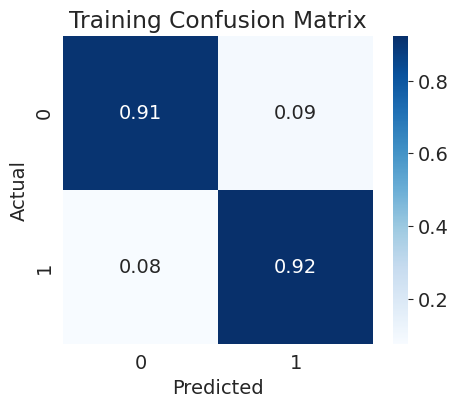

In [292]:
train_preds = predict_and_plot(X_train_scaled, y_train, 'Training')

Accuracy: 100.00%


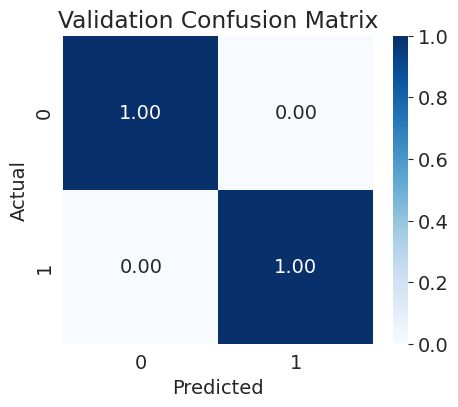

In [293]:
val_preds = predict_and_plot(X_val_scaled, y_val, 'Validation')

Accuracy: 100.00%


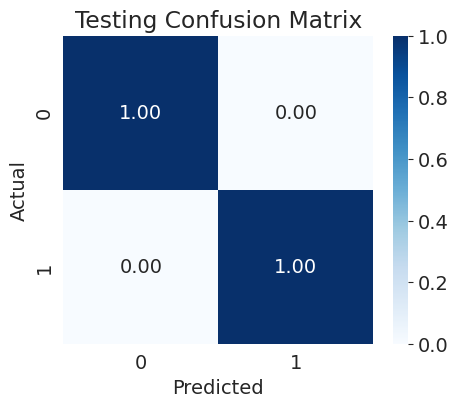

In [294]:
test_preds = predict_and_plot(X_test_scaled, y_test, 'Testing')

In [295]:
## Create the random prediction model
def random_guess(inputs):
    return np.random.choice([0, 1], len(inputs))

## Create the always-fail model
def all_no(inputs):
    return np.full(len(inputs), 0)

In [296]:
## Calculate their accuracy

accuracy_score(y_test,random_guess(X_test_scaled))

0.3333333333333333

In [297]:
accuracy_score(y_test,all_no(X_test_scaled))

0.3333333333333333

## Making Predictions on a Single Input

After training and evaluating our Logistic Regression model, we can use it to predict the examination outcome of an individual student based on their study hours.

In [298]:
## let's predict the result for a student who studies for 6 hours

new_student = pd.DataFrame({
    'Study_Hours': [6]
})

new_student_scaled = scaler.transform(new_student)

prediction = model.predict(new_student_scaled)

if prediction[0] == 1:
    print("Predicted Result: Pass")
else:
    print("Predicted Result: Fail")

Predicted Result: Pass


In [299]:
print("Coefficient:", model.coef_)
print("Intercept:", model.intercept_)

Coefficient: [[2.0339931]]
Intercept: [0.28106872]


### Model Interpretation

The Logistic Regression model produced a positive coefficient of approximately 2.03, indicating a positive relationship between study hours and the likelihood of passing an examination.

Since the study hours were standardized before training, this coefficient represents the change in log-odds of passing for a one-standard-deviation increase in study hours.

The intercept of approximately 0.28 represents the baseline log-odds of passing when study hours are at the training dataset's average.

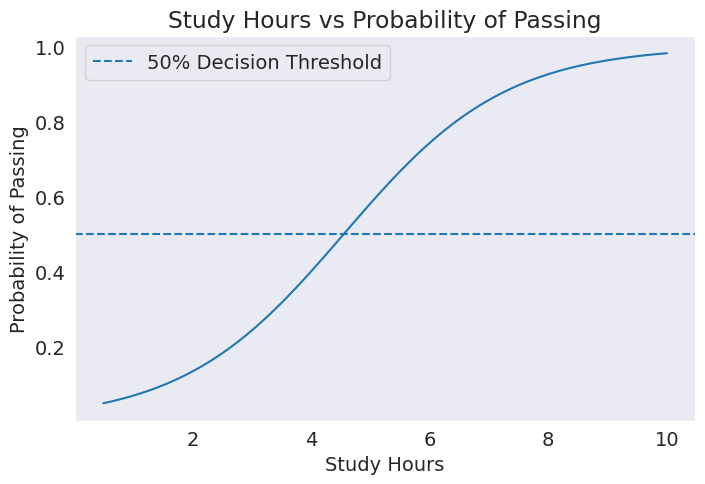

In [300]:
import numpy as np
import matplotlib.pyplot as plt

study_hours = np.linspace(
    student_df['Study_Hours'].min(),
    student_df['Study_Hours'].max(),
    100
)

study_hours_df = pd.DataFrame({
    'Study_Hours': study_hours
})

study_hours_scaled = scaler.transform(study_hours_df)

pass_probabilities = model.predict_proba(study_hours_scaled)[:, 1]

plt.figure(figsize=(8, 5))
plt.plot(study_hours, pass_probabilities)
plt.axhline(y=0.5, linestyle='--', label='50% Decision Threshold')

plt.xlabel('Study Hours')
plt.ylabel('Probability of Passing')
plt.title('Study Hours vs Probability of Passing')
plt.legend()
plt.grid()
plt.show()

## Conclusion

This project explored the use of Logistic Regression to predict students' examination outcomes based on their study hours.

The model achieved 87.5% training accuracy, 100% validation accuracy and 100% test accuracy on the available data. The positive model coefficient indicates that increased study hours are associated with a higher predicted likelihood of passing.

However, the dataset contains only 30 student records, and the test set contains only three students, all of whom passed. Therefore, the evaluation results should not be treated as evidence of strong generalization.

Future improvements could include collecting more student records and incorporating additional features such as attendance, previous examination scores and class participation.